#### Import Necessary Libraries

In [93]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
import math

#### Import the Dataset

In [94]:
df = pd.read_excel('premiums_with_life_style.xlsx')
print(df.shape)
df.head()

(10000, 15)


,Age,Gender,Region,Marital_status,Physical_Activity,Stress_Level,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,56,Female,Southeast,Unmarried,Medium,Medium,2,Normal,No Smoking,Self-Employed,25L - 40L,37,High blood pressure,Gold,27944
1,38,Female,Northeast,Married,Low,High,5,Overweight,Occasional,Freelancer,10L - 25L,10,No Disease,Silver,21108
2,18,Female,Southwest,Unmarried,Medium,High,0,Normal,No Smoking,Freelancer,<10L,9,No Disease,Bronze,8459
3,55,Male,Northeast,Married,High,Medium,3,Overweight,Occasional,Salaried,<10L,9,Thyroid,Silver,21685
4,22,Male,Southeast,Unmarried,Medium,High,2,Normal,Regular,Self-Employed,10L - 25L,13,High blood pressure & Heart disease,Bronze,15984


In [95]:
df.columns = df.columns.str.replace(' ','_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'number_of_dependants', 'bmi_category',
       'smoking_status', 'employment_status', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount'],
      dtype='object')

### Exploratory Data Analysis & Data Cleaning
#### Check if the dataset contains Null value

In [96]:
df.isna().sum()

age                       0
gender                    0
region                    0
marital_status            0
physical_activity         0
stress_level              0
number_of_dependants      0
bmi_category              0
smoking_status            9
employment_status         7
income_level             18
income_lakhs              0
medical_history           0
insurance_plan            0
annual_premium_amount     0
dtype: int64

In [97]:
df.dropna(inplace=True)
df.isna().sum()

age                      0
gender                   0
region                   0
marital_status           0
physical_activity        0
stress_level             0
number_of_dependants     0
bmi_category             0
smoking_status           0
employment_status        0
income_level             0
income_lakhs             0
medical_history          0
insurance_plan           0
annual_premium_amount    0
dtype: int64

#### Check if is there have any duplicate record present in this dataset

In [98]:
df.duplicated().sum()

np.int64(0)

In [99]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

#### Describe the Dataset

In [100]:
df.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,9973.000000,9973.000000,9973.000000,9973.000000
mean,41.319362,3.195628,23.382232,19503.816705
std,58.044687,21.679565,32.334811,8898.079736
min,18.000000,0.000000,1.000000,3582.000000
25%,24.000000,0.000000,6.000000,11774.000000
50%,37.000000,2.000000,16.000000,19314.000000
75%,50.000000,3.000000,31.000000,26500.000000
max,1178.000000,456.000000,960.000000,45854.000000


In [101]:
numeric_features = df.select_dtypes(exclude='object').columns
numeric_features

Index(['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount'], dtype='object')

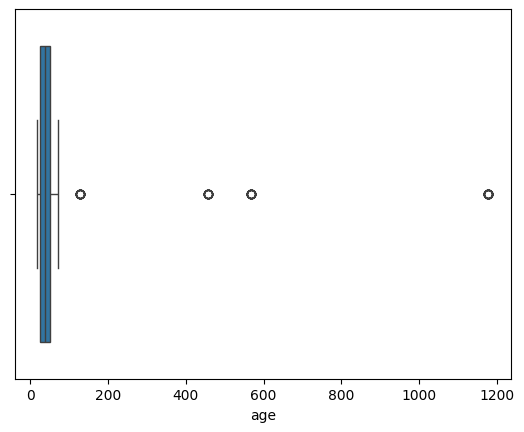

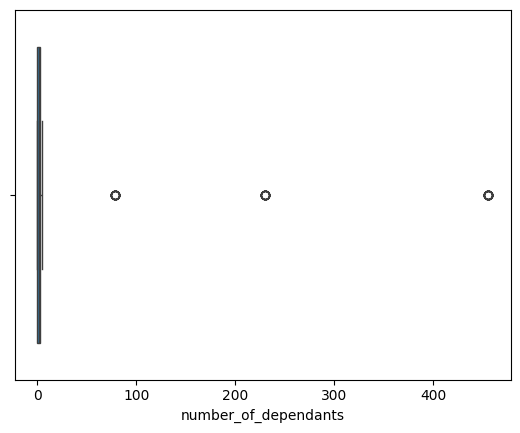

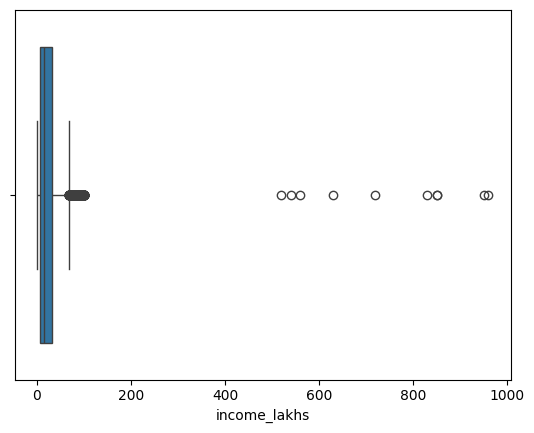

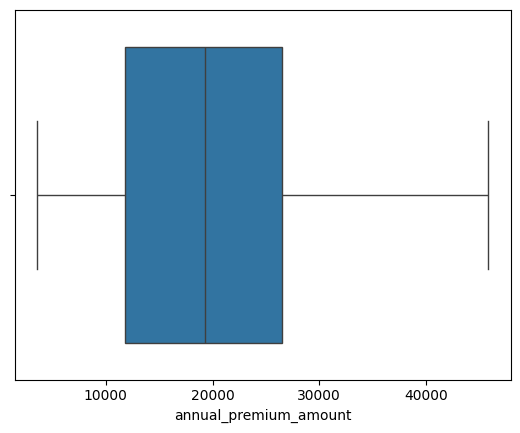

In [102]:
for feature in numeric_features:
    sns.boxplot(df[feature],orient='h')
    plt.show()

#### Treating the Outliers: **Age**

In [103]:
df.age.quantile(0.99)

np.float64(71.0)

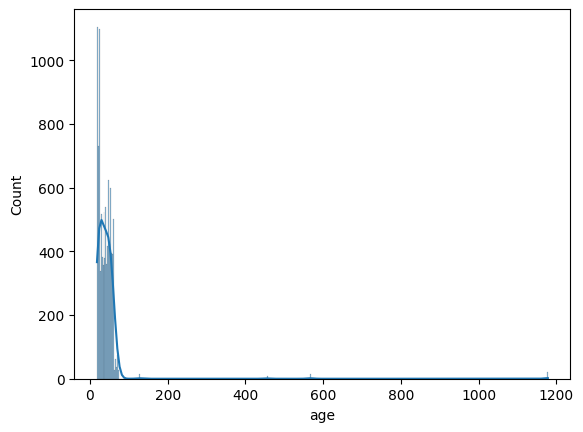

In [104]:
sns.histplot(df.age,kde=True)
plt.show()

From the Business Knowledge, We set the Age limit is 100

In [105]:
df[df.age>100].shape

(58, 15)

In [106]:
df2 = df[df.age<=100].copy()
df2.shape

(9915, 15)

In [107]:
df2.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,9915.000000,9915.000000,9915.000000,9915.000000
mean,37.743621,3.203429,23.400807,19496.715784
std,13.975462,21.742340,32.398236,8899.088302
min,18.000000,0.000000,1.000000,3582.000000
25%,24.000000,0.000000,6.000000,11765.500000
50%,37.000000,2.000000,16.000000,19309.000000
75%,50.000000,3.000000,31.000000,26493.000000
max,72.000000,456.000000,960.000000,45854.000000


#### Treating the Outliers: **Number of Dependants**

In [108]:
df.number_of_dependants.unique()

array([  2,   5,   0,   3,   1,   4, 456,  78, 230])

In [109]:
df.number_of_dependants.value_counts()

number_of_dependants
0      2626
3      2441
2      1916
1      1432
4      1096
5       415
456      19
78       15
230      13
Name: count, dtype: int64

For this outlier, we drop the record which have more then 5 Dependaants

In [110]:
df2[df2.number_of_dependants>5].shape

(47, 15)

In [111]:
df3 = df2[df2.number_of_dependants<=5].copy()
df3.shape

(9868, 15)

In [112]:
df3.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount
count,9868.000000,9868.000000,9868.000000,9868.000000
mean,37.756486,1.919133,23.411634,19511.417714
std,13.976822,1.503264,32.437621,8900.941540
min,18.000000,0.000000,1.000000,3582.000000
25%,24.000000,0.000000,6.000000,11776.250000
50%,37.000000,2.000000,16.000000,19327.500000
75%,50.000000,3.000000,31.000000,26505.250000
max,72.000000,5.000000,960.000000,45854.000000


#### Treating the Outliers: **Income**

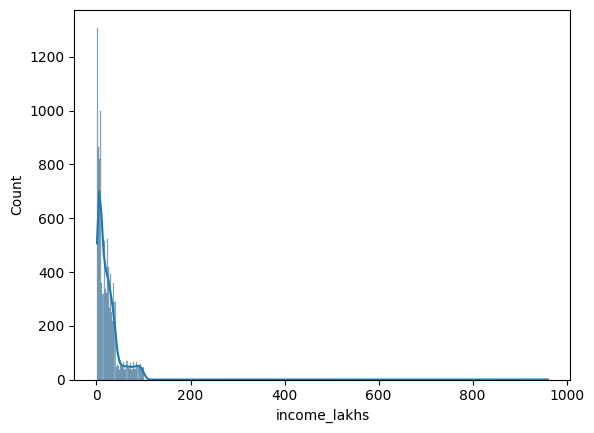

In [113]:
sns.histplot(df3.income_lakhs,kde=True)
plt.show()

In [114]:
df3.income_lakhs.quantile(0.99)

np.float64(97.0)

In [115]:
Q1,Q3 = df3.income_lakhs.quantile([0.25,0.75])
IQR = Q3 - Q1
lower = Q1 - 3*IQR
upper = Q3 + 3*IQR
lower, upper

(-69.0, 106.0)

We can use IQR with slight variation, but for now we use 100 as upper limit

In [116]:
df3[df3.income_lakhs>100].shape

(10, 15)

In [117]:
df4 = df3[df3.income_lakhs<=100].copy()
df4.shape

(9858, 15)

#### Treating the Outliers: **Annual Premium Amount**

For now there is no outlier we can detect

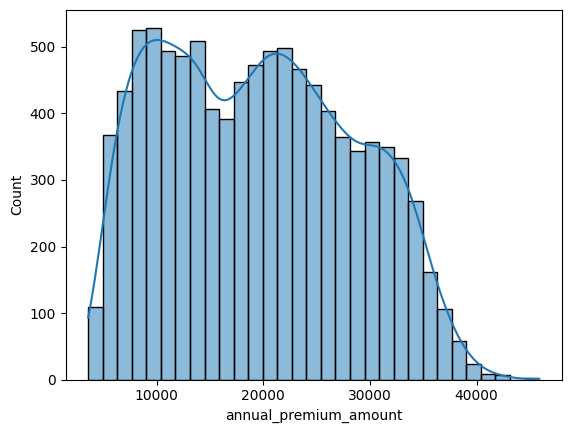

In [118]:
sns.histplot(df4.annual_premium_amount,kde=True)
plt.show()

### EDA on Categorical Features

In [119]:
categorical_features = df4.select_dtypes(include='object').columns
categorical_features

Index(['gender', 'region', 'marital_status', 'physical_activity',
       'stress_level', 'bmi_category', 'smoking_status', 'employment_status',
       'income_level', 'medical_history', 'insurance_plan'],
      dtype='object')

In [120]:
for feature in categorical_features:
    print(f"{feature}: {df[feature].unique()}")

gender: ['Female' 'Male']
region: ['Southeast' 'Northeast' 'Southwest' 'Northwest']
marital_status: ['Unmarried' 'Married']
physical_activity: ['Medium' 'Low' 'High']
stress_level: ['Medium' 'High' 'Low']
bmi_category: ['Normal' 'Overweight' 'Obesity' 'Underweight']
smoking_status: ['No Smoking' 'Occasional' 'Regular']
employment_status: ['Self-Employed' 'Freelancer' 'Salaried']
income_level: ['25L - 40L' '10L - 25L' '<10L' '> 40L']
medical_history: ['High blood pressure' 'No Disease' 'Thyroid'
 'High blood pressure & Heart disease' 'Diabetes & Thyroid' 'Diabetes'
 'Heart disease' 'Diabetes & High blood pressure'
 'Diabetes & Heart disease']
insurance_plan: ['Gold' 'Silver' 'Bronze']


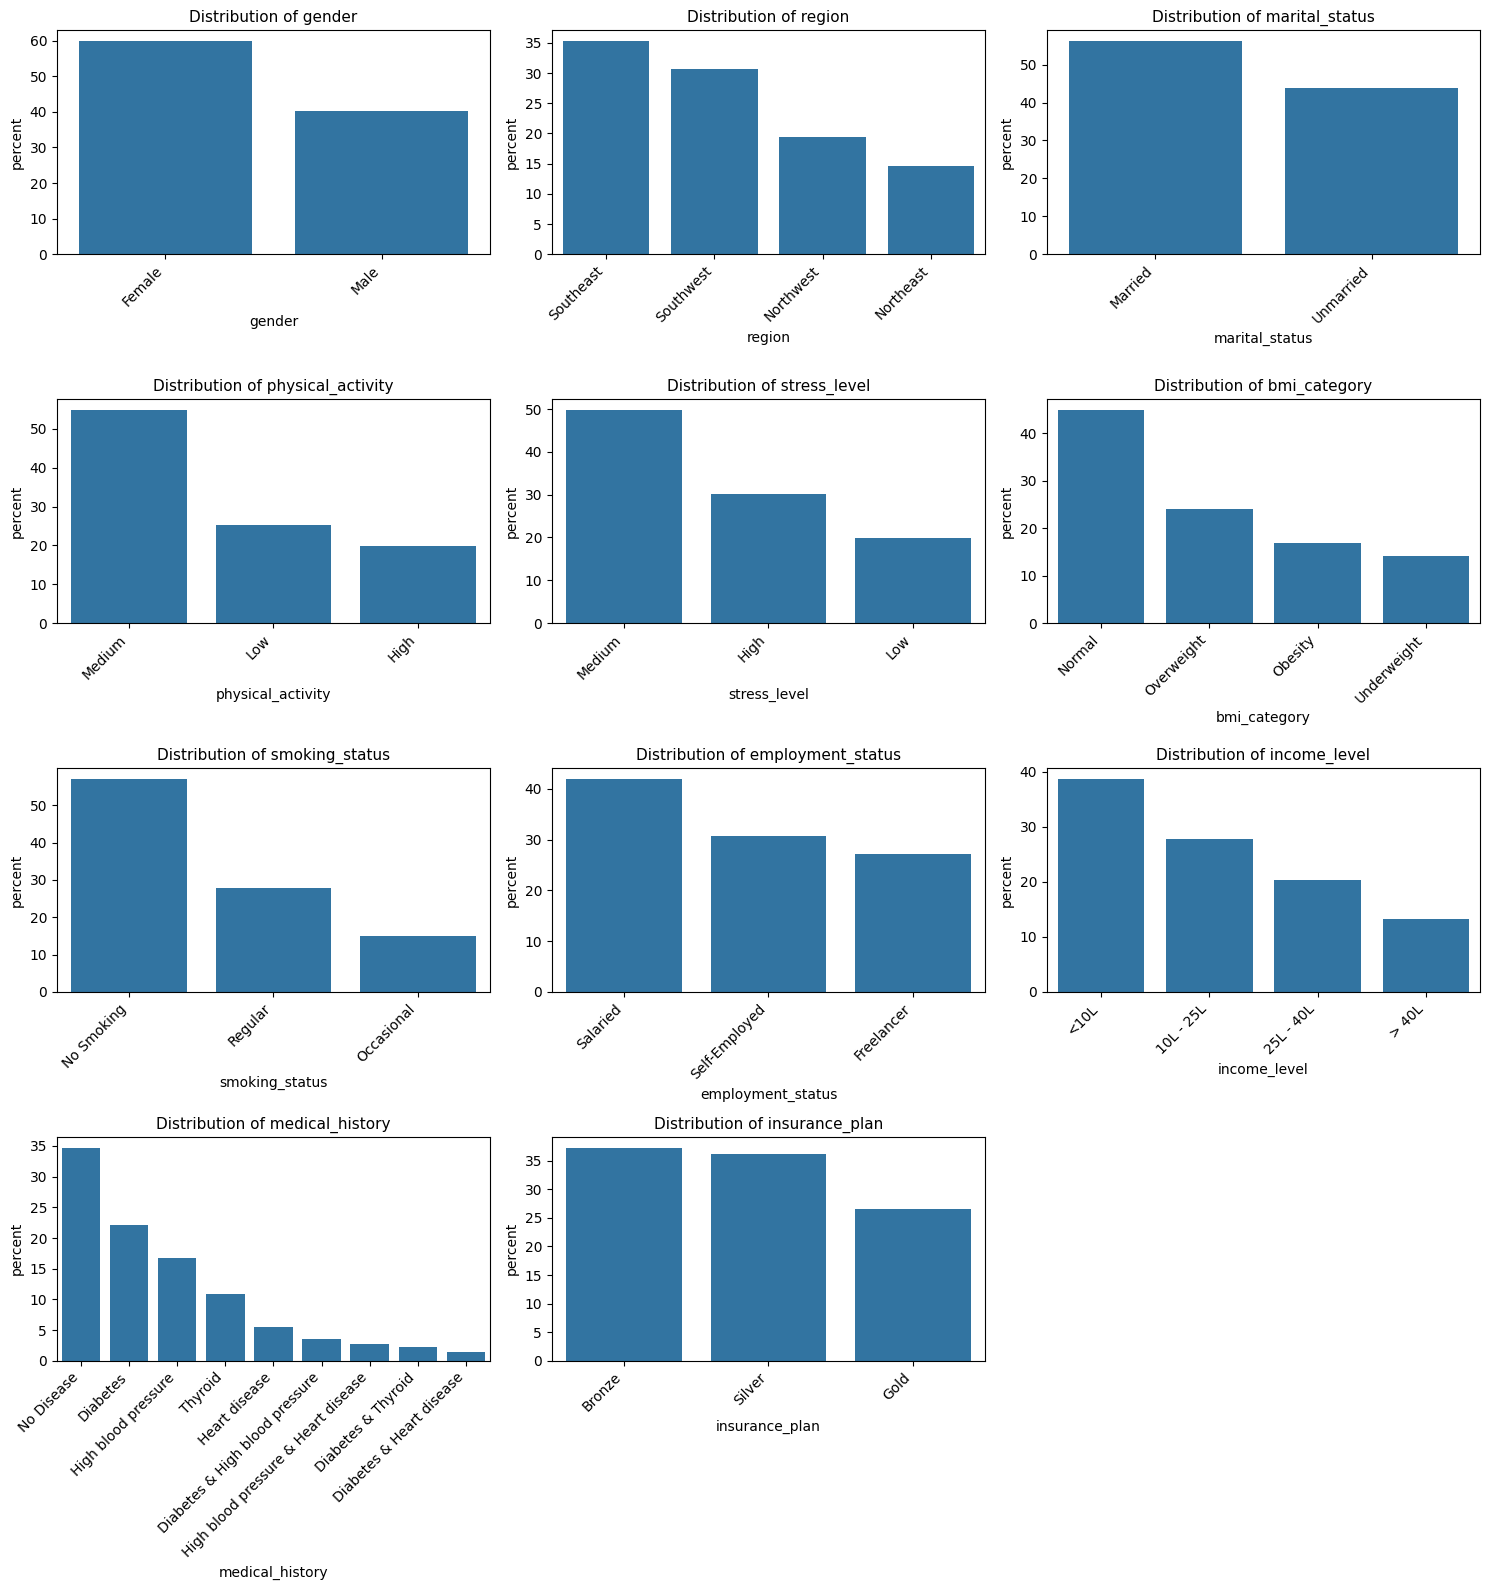

In [121]:
n_cols = 3
n_rows = math.ceil(len(categorical_features) / n_cols)

# Create the figure grid
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows))

# Flatten axes array so you can iterate with a single index
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    sorted_order = df4[feature].value_counts().index
    sns.countplot(data=df4, x=feature,order=sorted_order,stat='percent', ax=axes[i])
    axes[i].set_title(f"Distribution of {feature}", fontsize=11)
    axes[i].tick_params(axis="x", rotation=45)
    # Ensure rotated labels align cleanly to tick marks
    plt.setp(axes[i].get_xticklabels(), ha="right")

# Hide any unused subplots (if your feature count isn't an exact multiple of 3)
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

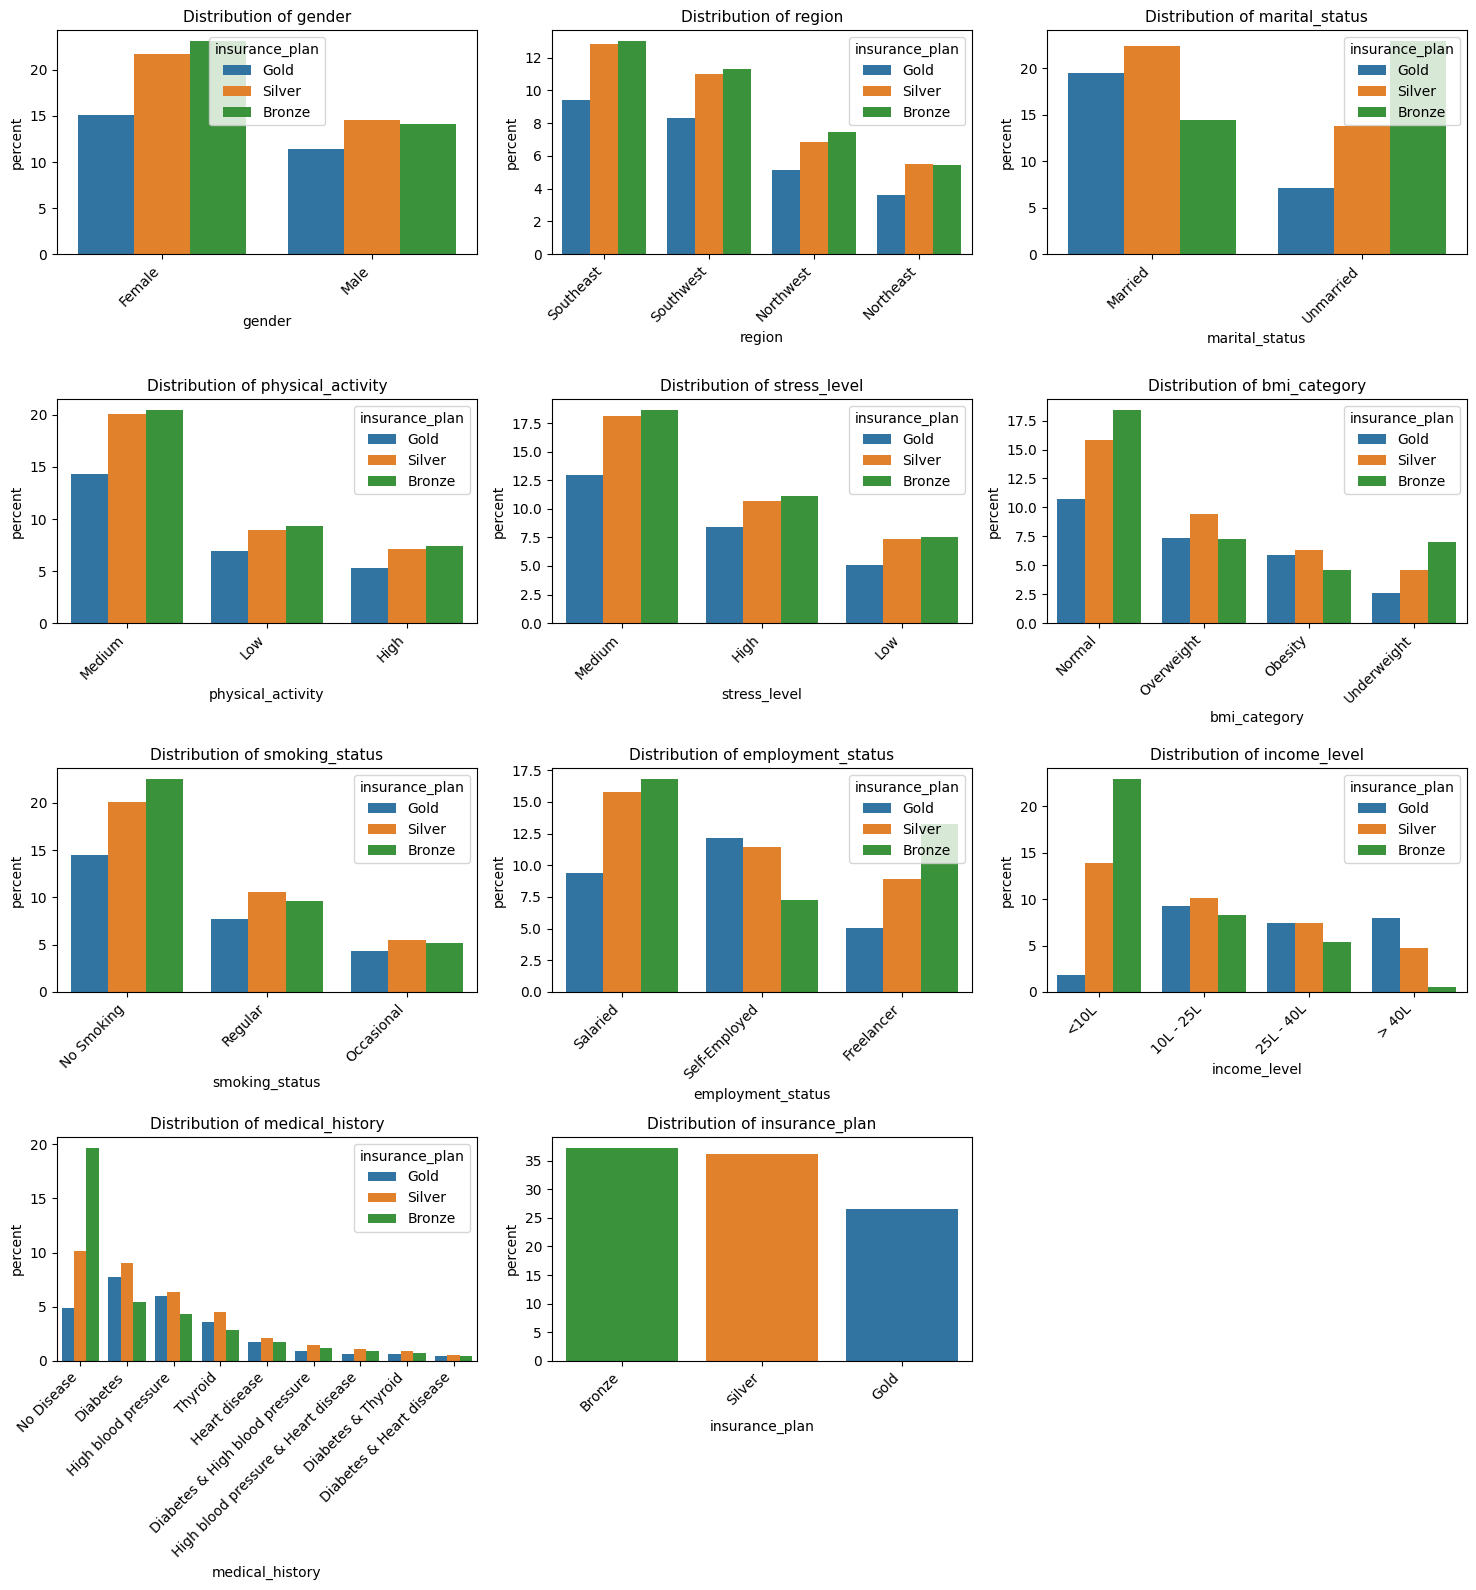

In [122]:
n_cols = 3
n_rows = math.ceil(len(categorical_features) / n_cols)

# Create the figure grid
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows))

# Flatten axes array so you can iterate with a single index
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    sorted_order = df4[feature].value_counts().index
    sns.countplot(data=df4, x=feature,hue='insurance_plan',stat='percent',order=sorted_order, ax=axes[i])
    axes[i].set_title(f"Distribution of {feature}", fontsize=11)
    axes[i].tick_params(axis="x", rotation=45)
    # Ensure rotated labels align cleanly to tick marks
    plt.setp(axes[i].get_xticklabels(), ha="right")

# Hide any unused subplots (if your feature count isn't an exact multiple of 3)
for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

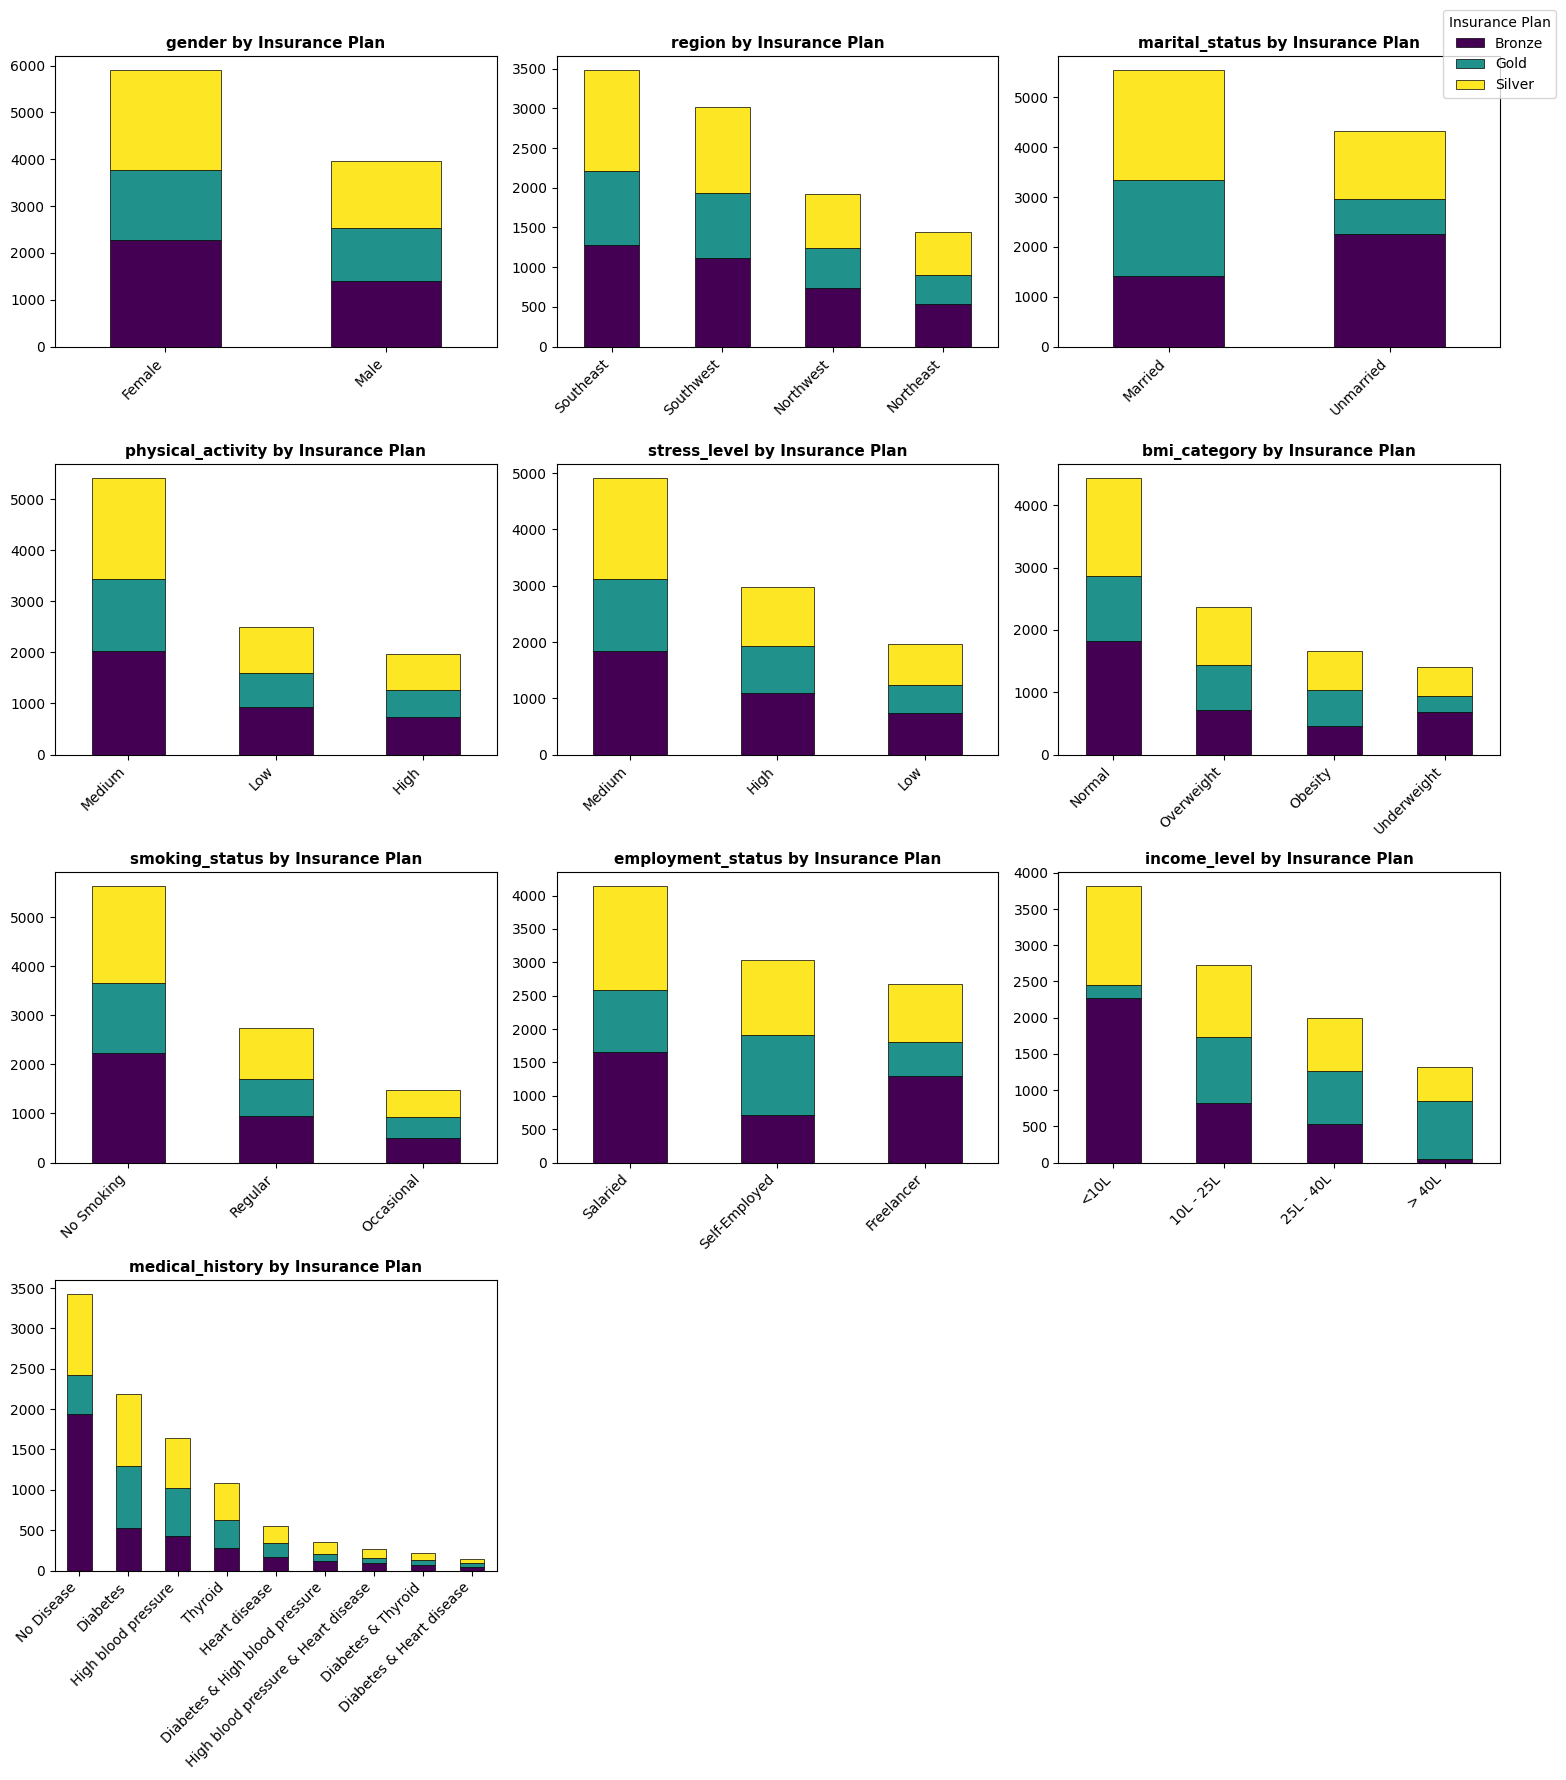

In [123]:
# Exclude insurance_plan from the features list if it's currently inside it
features_to_plot = [f for f in categorical_features if f != 'insurance_plan']

n_cols = 3
n_rows = math.ceil(len(features_to_plot) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    # 1. Create a frequency matrix of Feature vs Insurance Plan
    ct = pd.crosstab(df4[feature], df4['insurance_plan'])

    # 2. Sort categories by total count descending
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

    # 3. Plot stacked bars on the specific subplot axis
    ct.plot(
        kind='bar',
        stacked=True,
        ax=axes[i],
        colormap='viridis',  # Change colormap if preferred
        edgecolor='black',
        linewidth=0.5,
    )

    axes[i].set_title(f"{feature} by Insurance Plan", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    plt.setp(axes[i].get_xticklabels(), ha='right')

    # Remove individual legends to prevent clutter across subplots
    axes[i].get_legend().remove()

# Hide any empty subplot axes
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# 4. Add a single shared legend at the top or side
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Insurance Plan', loc='upper right', bbox_to_anchor=(0.98, 0.99))

plt.tight_layout(rect=[0, 0, 0.95, 0.98])
plt.show()

In [124]:
for feature in categorical_features:
    print(f"{feature}: {df[feature].unique()}")

gender: ['Female' 'Male']
region: ['Southeast' 'Northeast' 'Southwest' 'Northwest']
marital_status: ['Unmarried' 'Married']
physical_activity: ['Medium' 'Low' 'High']
stress_level: ['Medium' 'High' 'Low']
bmi_category: ['Normal' 'Overweight' 'Obesity' 'Underweight']
smoking_status: ['No Smoking' 'Occasional' 'Regular']
employment_status: ['Self-Employed' 'Freelancer' 'Salaried']
income_level: ['25L - 40L' '10L - 25L' '<10L' '> 40L']
medical_history: ['High blood pressure' 'No Disease' 'Thyroid'
 'High blood pressure & Heart disease' 'Diabetes & Thyroid' 'Diabetes'
 'Heart disease' 'Diabetes & High blood pressure'
 'Diabetes & Heart disease']
insurance_plan: ['Gold' 'Silver' 'Bronze']


### Feature Engineering


In [125]:
physical_activity = {
    'High' : 0, 
    'Medium' : 1, 
    'Low' : 4
    }
stress_level = {
    'High' : 4, 
    'Medium' : 1, 
    'Low' : 0
    }

In [126]:
df4['life_style_risk_score'] = df4.physical_activity.map(physical_activity) + df4.stress_level.map(stress_level)
df4['life_style_risk_score'].unique()

array([2, 8, 5, 1, 0, 4])

In [127]:
df4.drop(columns=['physical_activity','stress_level'],inplace=True)
df4.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,life_style_risk_score
0,56,Female,Southeast,Unmarried,2,Normal,No Smoking,Self-Employed,25L - 40L,37,High blood pressure,Gold,27944,2
1,38,Female,Northeast,Married,5,Overweight,Occasional,Freelancer,10L - 25L,10,No Disease,Silver,21108,8


In [128]:
df4.medical_history.unique()

array(['High blood pressure', 'No Disease', 'Thyroid',
       'High blood pressure & Heart disease', 'Diabetes & Thyroid',
       'Diabetes', 'Heart disease', 'Diabetes & High blood pressure',
       'Diabetes & Heart disease'], dtype=object)

In [129]:
df4[['disease_1', 'disease_2']] = df4.medical_history.str.split(' & ',expand=True).apply(lambda x: x.str.lower())
df4[['disease_1','disease_2']].isna().sum()

disease_1       0
disease_2    8882
dtype: int64

In [130]:
df4.disease_1.fillna('none',inplace=True)
df4.disease_2.fillna('none',inplace=True)
df4[['disease_1','disease_2']].isna().sum()

C:\Users\Admin\AppData\Local\Temp\ipykernel_11624\3629346642.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df4.disease_1.fillna('none',inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_11624\3629346642.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, w

disease_1    0
disease_2    0
dtype: int64

In [131]:
risk_scores = {
    "diabetes": 6,
    "heart disease": 8,
    "high blood pressure":6,
    "thyroid": 5,
    "no disease": 0,
    "none":0
}

df4['total_risk_score'] = df4.disease_1.map(risk_scores) + df4.disease_2.map(risk_scores)
df4['total_risk_score'].unique()

array([ 6,  0,  5, 14, 11,  8, 12])

#### Label Encoding: **insurance_plan, income_level**

In [132]:
df4.insurance_plan = df4.insurance_plan.map({'Gold':3, 'Silver':2, 'Bronze':1})
df4.insurance_plan.unique()

array([3, 2, 1])

In [133]:
df4.income_level = df4.income_level.map({'<10L':0, '10L - 25L':1, '25L - 40L':2, '> 40L':3})
df4.income_level.unique()

array([2, 1, 0, 3])

In [134]:
df4.head()

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,life_style_risk_score,disease_1,disease_2,total_risk_score
0,56,Female,Southeast,Unmarried,2,Normal,No Smoking,Self-Employed,2,37,High blood pressure,3,27944,2,high blood pressure,none,6
1,38,Female,Northeast,Married,5,Overweight,Occasional,Freelancer,1,10,No Disease,2,21108,8,no disease,none,0
2,18,Female,Southwest,Unmarried,0,Normal,No Smoking,Freelancer,0,9,No Disease,1,8459,5,no disease,none,0
3,55,Male,Northeast,Married,3,Overweight,Occasional,Salaried,0,9,Thyroid,2,21685,1,thyroid,none,5
4,22,Male,Southeast,Unmarried,2,Normal,Regular,Self-Employed,1,13,High blood pressure & Heart disease,1,15984,5,high blood pressure,heart disease,14


Drop medical_history, disease_1, disease_2 features because we produce a new feature based on this

In [135]:
df4.drop(columns=['medical_history','disease_1','disease_2'],inplace=True)
df4.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'insurance_plan', 'annual_premium_amount',
       'life_style_risk_score', 'total_risk_score'],
      dtype='object')

### One Hot Encoding
#### Rest of the features which is Nominal Feature



In [136]:
df4.head()

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,insurance_plan,annual_premium_amount,life_style_risk_score,total_risk_score
0,56,Female,Southeast,Unmarried,2,Normal,No Smoking,Self-Employed,2,37,3,27944,2,6
1,38,Female,Northeast,Married,5,Overweight,Occasional,Freelancer,1,10,2,21108,8,0
2,18,Female,Southwest,Unmarried,0,Normal,No Smoking,Freelancer,0,9,1,8459,5,0
3,55,Male,Northeast,Married,3,Overweight,Occasional,Salaried,0,9,2,21685,1,5
4,22,Male,Southeast,Unmarried,2,Normal,Regular,Self-Employed,1,13,1,15984,5,14


In [137]:
nominal_feature = df4.select_dtypes(include='object').columns
nominal_feature

Index(['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status',
       'employment_status'],
      dtype='object')

In [138]:
df5 = pd.get_dummies(data=df4, columns=nominal_feature,drop_first=True, dtype='int')
df5.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,life_style_risk_score,total_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,56,2,2,37,3,27944,2,6,0,0,1,0,1,0,0,0,0,0,0,1
1,38,5,1,10,2,21108,8,0,0,0,0,0,0,0,1,0,1,0,0,0
2,18,0,0,9,1,8459,5,0,0,0,0,1,1,0,0,0,0,0,0,0
3,55,3,0,9,2,21685,1,5,1,0,0,0,0,0,1,0,1,0,1,0
4,22,2,1,13,1,15984,5,14,1,0,1,0,1,0,0,0,0,1,0,1


#### Feature scaling

In [139]:
X = df5.drop(columns=['annual_premium_amount'])
y = df5.annual_premium_amount

In [140]:
X.head(2)

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,life_style_risk_score,total_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,56,2,2,37,3,2,6,0,0,1,0,1,0,0,0,0,0,0,1
1,38,5,1,10,2,8,0,0,0,0,0,0,0,1,0,1,0,0,0


In [141]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    viff_df = pd.DataFrame()
    viff_df['var'] = data.columns
    viff_df['viff'] = [variance_inflation_factor(data.values, i) for i in range(len(data.columns))]
    return viff_df

In [142]:
calculate_vif(X)

,var,viff
0,age,1.993284
1,number_of_dependants,3.326672
2,income_level,6.153287
3,income_lakhs,5.664192
4,insurance_plan,1.826983
5,life_style_risk_score,1.001814
6,total_risk_score,1.298650
7,gender_Male,1.153454
8,region_Northwest,1.883189
9,region_Southeast,2.218834


In [143]:
calculate_vif(X.drop(columns=['income_level']))

,var,viff
0,age,1.967995
1,number_of_dependants,3.326621
2,income_lakhs,1.288539
3,insurance_plan,1.706543
4,life_style_risk_score,1.001812
5,total_risk_score,1.298414
6,gender_Male,1.149322
7,region_Northwest,1.882802
8,region_Southeast,2.218634
9,region_Southwest,2.154591


In [144]:
X_reduced = X.drop(columns=['income_level'])

In [145]:
X_reduced.head()

,age,number_of_dependants,income_lakhs,insurance_plan,life_style_risk_score,total_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,56,2,37,3,2,6,0,0,1,0,1,0,0,0,0,0,0,1
1,38,5,10,2,8,0,0,0,0,0,0,0,1,0,1,0,0,0
2,18,0,9,1,5,0,0,0,0,1,1,0,0,0,0,0,0,0
3,55,3,9,2,1,5,1,0,0,0,0,0,1,0,1,0,1,0
4,22,2,13,1,5,14,1,0,1,0,1,0,0,0,0,1,0,1


In [146]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_reduced[X_reduced.columns] = scaler.fit_transform(X_reduced)

In [147]:
X_train,X_test,y_train,y_test = train_test_split(X_reduced,y,test_size=0.3,random_state=42)

In [148]:
lr_model = LinearRegression()
lr_model.fit(X_train,y_train)

print("LR score: ",lr_model.score(X_test,y_test))
y_pred = lr_model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("RMSE:",root_mean_squared_error(y_test,y_pred))

LR score:  0.957877163116046
MSE : 3271494.4534015628
RMSE: 1808.727302110952


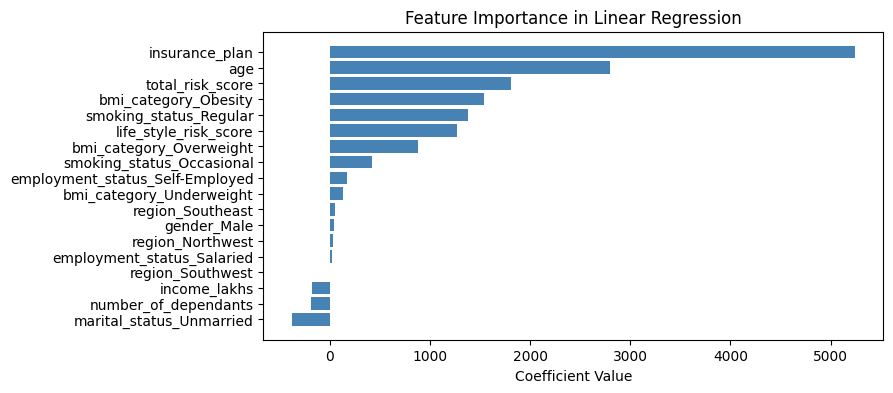

In [149]:
feature_importance = lr_model.coef_

df_fi = pd.DataFrame(data=feature_importance,index=X_reduced.columns,columns=['Coefficient'])
df_fi.sort_values(by='Coefficient', ascending=True,inplace=True)

plt.figure(figsize=(8, 4))
plt.barh(df_fi.index, df_fi['Coefficient'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()


In [150]:
lasso_model = Lasso()
lasso_model.fit(X_train,y_train)

print("Lasso score: ",lasso_model.score(X_test,y_test))
y_pred = lasso_model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("RMSE:",root_mean_squared_error(y_test,y_pred)) 

Lasso score:  0.9578764095230048
MSE : 3271552.981640315
RMSE: 1808.743481436855


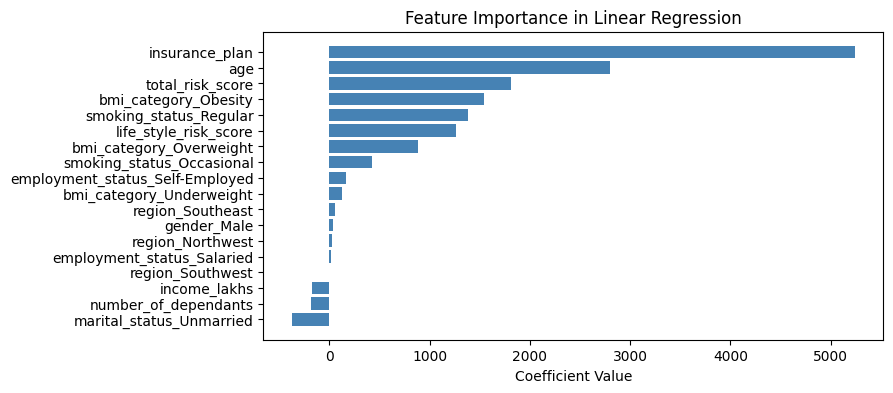

In [151]:
feature_importance = lasso_model.coef_

df_fi = pd.DataFrame(data=feature_importance,index=X_reduced.columns,columns=['Coefficient'])
df_fi.sort_values(by='Coefficient', ascending=True,inplace=True)

plt.figure(figsize=(8, 4))
plt.barh(df_fi.index, df_fi['Coefficient'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

In [152]:
ridge_model = Ridge()
ridge_model.fit(X_train,y_train)

print("Ridge score: ",ridge_model.score(X_test,y_test))
y_pred = ridge_model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("RMSE:",root_mean_squared_error(y_test,y_pred))

Ridge score:  0.9578759540784435
MSE : 3271588.3540052013
RMSE: 1808.7532595700281


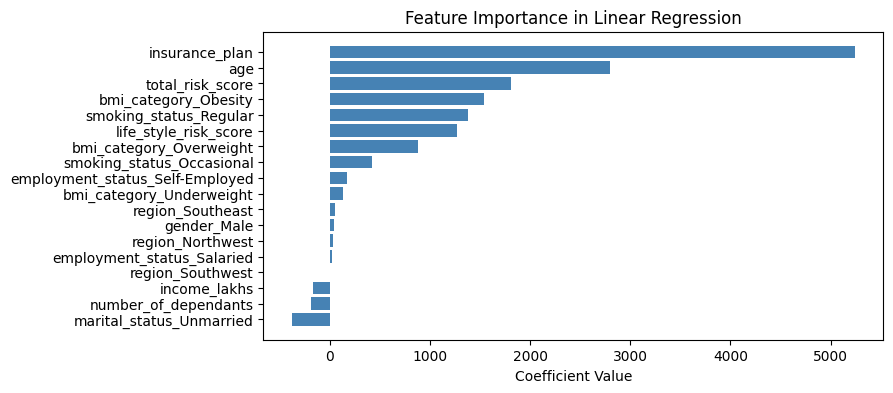

In [153]:
feature_importance = ridge_model.coef_

df_fi = pd.DataFrame(data=feature_importance,index=X_reduced.columns,columns=['Coefficient'])
df_fi.sort_values(by='Coefficient', ascending=True,inplace=True)

plt.figure(figsize=(8, 4))
plt.barh(df_fi.index, df_fi['Coefficient'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

In [154]:
rf_model = RandomForestRegressor()
rf_model.fit(X_train,y_train)

print("RF score: ",rf_model.score(X_test,y_test))
y_pred = rf_model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("RMSE:",root_mean_squared_error(y_test,y_pred))

RF score:  0.9904018135987823
MSE : 745448.6900016821
RMSE: 863.3937050973224


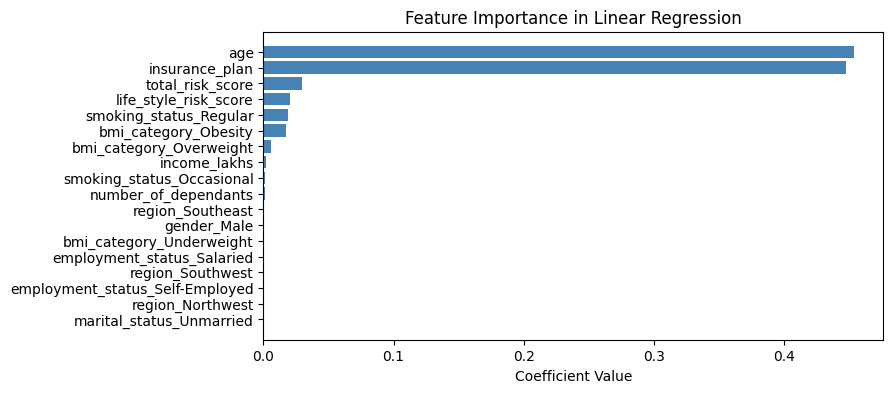

In [155]:
feature_importance = rf_model.feature_importances_

df_fi = pd.DataFrame(data=feature_importance,index=X_reduced.columns,columns=['Coefficient'])
df_fi.sort_values(by='Coefficient', ascending=True,inplace=True)

plt.figure(figsize=(8, 4))
plt.barh(df_fi.index, df_fi['Coefficient'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

In [156]:
xgb_model = XGBRegressor()
xgb_model.fit(X_train,y_train)

print("XGB score: ",xgb_model.score(X_test,y_test))
y_pred = xgb_model.predict(X_test)
print("MSE :",mean_squared_error(y_test,y_pred))
print("RMSE:",root_mean_squared_error(y_test,y_pred))

XGB score:  0.993882417678833
MSE : 475123.53125
RMSE: 689.2920532226562


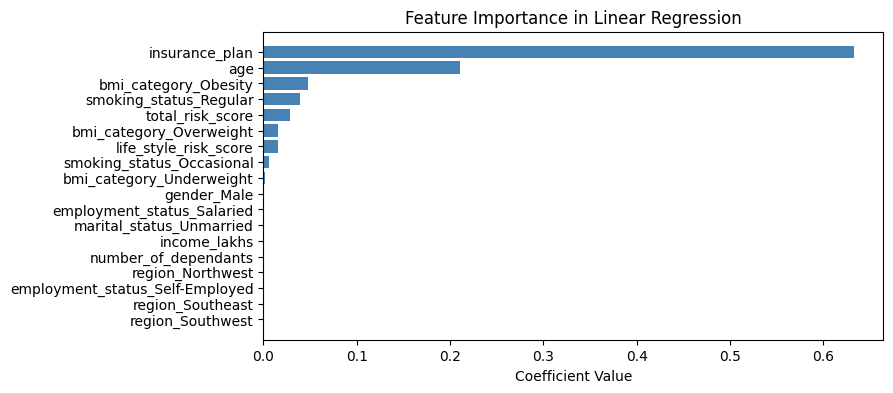

In [157]:
feature_importance = xgb_model.feature_importances_

df_fi = pd.DataFrame(data=feature_importance,index=X_reduced.columns,columns=['Coefficient'])
df_fi.sort_values(by='Coefficient', ascending=True,inplace=True)

plt.figure(figsize=(8, 4))
plt.barh(df_fi.index, df_fi['Coefficient'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

#### Model Evaluation

In [158]:
from sklearn.model_selection import RandomizedSearchCV

model = RandomizedSearchCV(
    estimator=XGBRegressor(),
    param_distributions={
    "max_depth": [3, 6, 9],
    "min_child_weight": [1, 5],
    "n_estimators": [150, 300, 600],
    "learning_rate": [0.03, 0.1, 0.2],
    "subsample": [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0],
    "gamma": [0, 0.2, 1.0],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [0.1, 1.0, 10.0]
    },
    cv=5,
    n_iter=10
)
model.fit(X_train,y_train)

,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.7, 0.9, ...], 'gamma': [0, 0.2, ...], 'learning_rate': [0.03, 0.1, ...], 'max_depth': [3, 6, ...], ...}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [159]:
best_model = model.best_estimator_
best_model

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [160]:
model.best_params_

{'subsample': 0.9,
 'reg_lambda': 1.0,
 'reg_alpha': 0,
 'n_estimators': 600,
 'min_child_weight': 1,
 'max_depth': 3,
 'learning_rate': 0.2,
 'gamma': 1.0,
 'colsample_bytree': 0.9}

In [161]:
model.best_score_

np.float64(0.9948217988014221)

In [162]:
y_pred = model.predict(X_test)

diff = y_test - y_pred
diff_pct = (diff*100)/y_test

In [163]:
diff_df = pd.DataFrame({
    'y_test': y_test,
    'y_pred': y_pred,
    'diff': diff,
    'diff_pct': diff_pct
})

diff_df.head()

,y_test,y_pred,diff,diff_pct
8496,30733,30536.185547,196.814453,0.640401
507,32997,32666.953125,330.046875,1.000233
5147,15251,15802.815430,-551.815430,-3.618225
887,6936,7615.366211,-679.366211,-9.794784
8848,10909,11887.553711,-978.553711,-8.970150


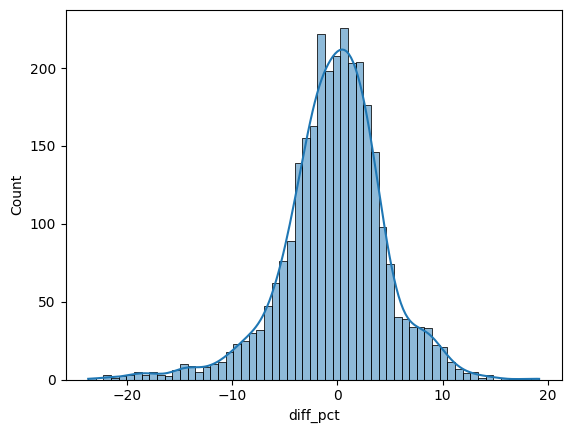

In [164]:
sns.histplot(diff_df.diff_pct,kde=True)
plt.show()

The error percentage is occured more than 10 percent in both tails, so we must find the percentage of extreme error which is above 10 percent error on Both tails.



In [165]:
extreme_diff = diff[abs(diff_df.diff_pct)>10].index
extreme_diff

Index([6110, 1918, 6092, 6559, 4861, 9814, 4635,   82, 6777, 1518,
       ...
       7112, 1404, 2985, 6601, 3474, 6779, 8484, 9940, 1042, 2863],
      dtype='int64', length=151)

In [167]:
extreme_diff.shape[0]*100/X_test.shape[0]

5.104800540906018

The percentage of extreme error(High margin Error) is around 5% which is under the limit based on our current requirements, which is around 5% percent of the customer will get either under or overprice than 10 percent.

In [169]:
from joblib import dump

dump(best_model,"artifacts/best_model.joblib")
dump(scaler,"artifacts/scaler.joblib")

['artifacts/scaler.joblib']